# Exploracion de datos

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

In [2]:
# Configuración visual de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Definir rutas relativas seguras desde la carpeta notebooks/
BASE_DIR = Path.cwd().parent
DATA_RAW = BASE_DIR / "data" / "raw"
CSV_PATH = DATA_RAW / "driver_imgs_list.csv"

# En caso de que descomprimieras imgs/imgs/train o directamente imgs/train
TRAIN_DIR = DATA_RAW / "imgs" / "train"
if not TRAIN_DIR.exists():
    TRAIN_DIR = DATA_RAW / "train"

print(f"Ruta datos crudos: {DATA_RAW}")
print(f"¿Existe archivo CSV?: {CSV_PATH.exists()}")
print(f"¿Existe carpeta train?: {TRAIN_DIR.exists()}")

Ruta datos crudos: c:\Users\JUANP\OneDrive\Escritorio\CursoIA\SafeRoute\data\raw
¿Existe archivo CSV?: True
¿Existe carpeta train?: True


# Diccionario de clases y nombres descriptivos

In [3]:
# Mapeo de las 10 categorías oficiales de State Farm
CLASSES_MAP = {
    'c0': 'Conducción segura y atenta',
    'c1': 'Escribiendo texto (mano derecha)',
    'c2': 'Hablando por teléfono (mano derecha)',
    'c3': 'Escribiendo texto (mano izquierda)',
    'c4': 'Hablando por teléfono (mano izquierda)',
    'c5': 'Operando la radio / tablero',
    'c6': 'Bebiendo líquidos',
    'c7': 'Alcanzando objeto atrás',
    'c8': 'Arreglándose pelo / maquillaje',
    'c9': 'Hablando con copiloto / distraído'
}

CLASSES_MAP_SHORT = {
    'c0': 'Segura',
    'c1': 'Texto (Der)',
    'c2': 'Llamada (Der)',
    'c3': 'Texto (Izq)',
    'c4': 'Llamada (Izq)',
    'c5': 'Radio',
    'c6': 'Bebiendo',
    'c7': 'Alcanzar atrás',
    'c8': 'Pelo/Maquillaje',
    'c9': 'Copiloto'
}

# Carga e inspección preliminar de metadatos

In [4]:
# Carga del archivo driver_imgs_list.csv
df = pd.read_csv(CSV_PATH)

print("Primeros 5 registros:")
display(df.head())

print("\nInformación estructural del DataFrame:")
print(df.info())

print(f"\nTotal de imágenes registradas: {len(df)}")
print(f"Total de sujetos (conductores únicos): {df['subject'].nunique()}")
print(f"Valores nulos en el dataset:\n{df.isnull().sum()}")

Primeros 5 registros:


,subject,classname,img
0,p012,c0,img_10206.jpg
1,p012,c0,img_27079.jpg
2,p012,c0,img_50749.jpg
3,p012,c0,img_97089.jpg
4,p012,c0,img_37741.jpg



Información estructural del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 34924 entries, 0 to 34923
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   subject    34924 non-null  str  
 1   classname  34924 non-null  str  
 2   img        34924 non-null  str  
dtypes: str(3)
memory usage: 818.7 KB
None

Total de imágenes registradas: 34924
Total de sujetos (conductores únicos): 20
Valores nulos en el dataset:
subject      0
classname    0
img          0
dtype: int64


# Análisis del balance de clases (Variable objetivo)

,Clase,Cantidad,Descripcion,Porcentaje (%)
0,c0,3906,Conducción segura y atenta,11.18
1,c1,3508,Escribiendo texto (mano derecha),10.04
2,c2,3566,Hablando por teléfono (mano derecha),10.21
3,c3,3618,Escribiendo texto (mano izquierda),10.36
4,c4,3634,Hablando por teléfono (mano izquierda),10.41
5,c5,3608,Operando la radio / tablero,10.33
6,c6,3622,Bebiendo líquidos,10.37
7,c7,3064,Alcanzando objeto atrás,8.77
8,c8,3036,Arreglándose pelo / maquillaje,8.69
9,c9,3362,Hablando con copiloto / distraído,9.63


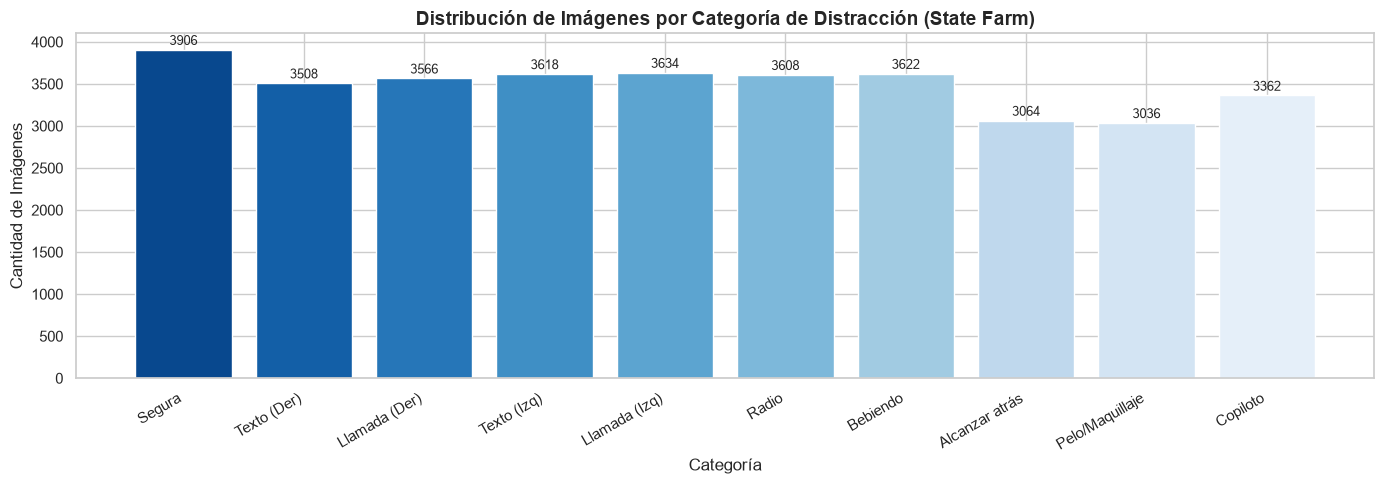

In [5]:
# Conteo por clase
class_counts = df['classname'].value_counts().sort_index().reset_index()
class_counts.columns = ['Clase', 'Cantidad']
class_counts['Descripcion'] = class_counts['Clase'].map(CLASSES_MAP)
class_counts['Porcentaje (%)'] = (class_counts['Cantidad'] / len(df) * 100).round(2)

display(class_counts)

# Gráfico de barras
plt.figure(figsize=(14, 5))
bars = plt.bar(class_counts['Clase'].map(CLASSES_MAP_SHORT), class_counts['Cantidad'], color=sns.color_palette("Blues_r", 10))

plt.title('Distribución de Imágenes por Categoría de Distracción (State Farm)', fontsize=14, weight='bold')
plt.xlabel('Categoría', fontsize=12)
plt.ylabel('Cantidad de Imágenes', fontsize=12)
plt.xticks(rotation=30, ha='right')

# Etiquetas sobre las barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 25, f"{int(yval)}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Distribución de imágenes por conductor (Sujeto)

C:\Users\JUANP\AppData\Local\Temp\ipykernel_16588\1611104847.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=subject_counts.index, y=subject_counts.values, palette="crest")


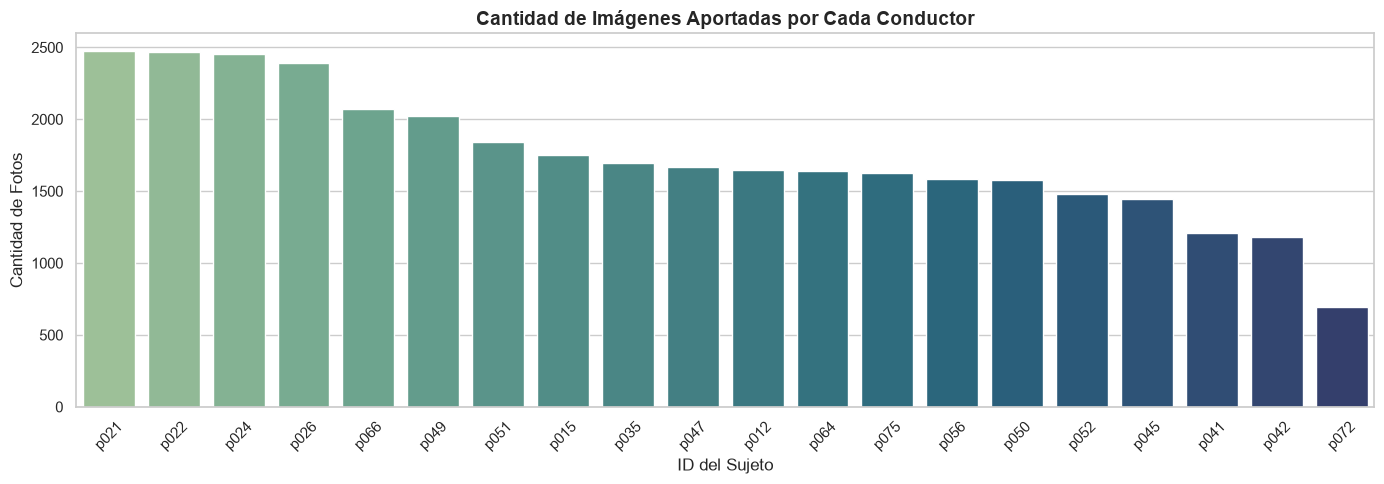

Promedio de fotos por conductor: 1746.2
Mínimo: 692 imágenes | Máximo: 2474 imágenes


In [6]:
# Conteo de imágenes que aportó cada sujeto
subject_counts = df['subject'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(14, 5))
sns.barplot(x=subject_counts.index, y=subject_counts.values, palette="crest")
plt.title('Cantidad de Imágenes Aportadas por Cada Conductor', fontsize=14, weight='bold')
plt.xlabel('ID del Sujeto', fontsize=12)
plt.ylabel('Cantidad de Fotos', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Promedio de fotos por conductor: {subject_counts.mean():.1f}")
print(f"Mínimo: {subject_counts.min()} imágenes | Máximo: {subject_counts.max()} imágenes")

# Muestra visual de cada clase (Una imagen representativa por categoría)

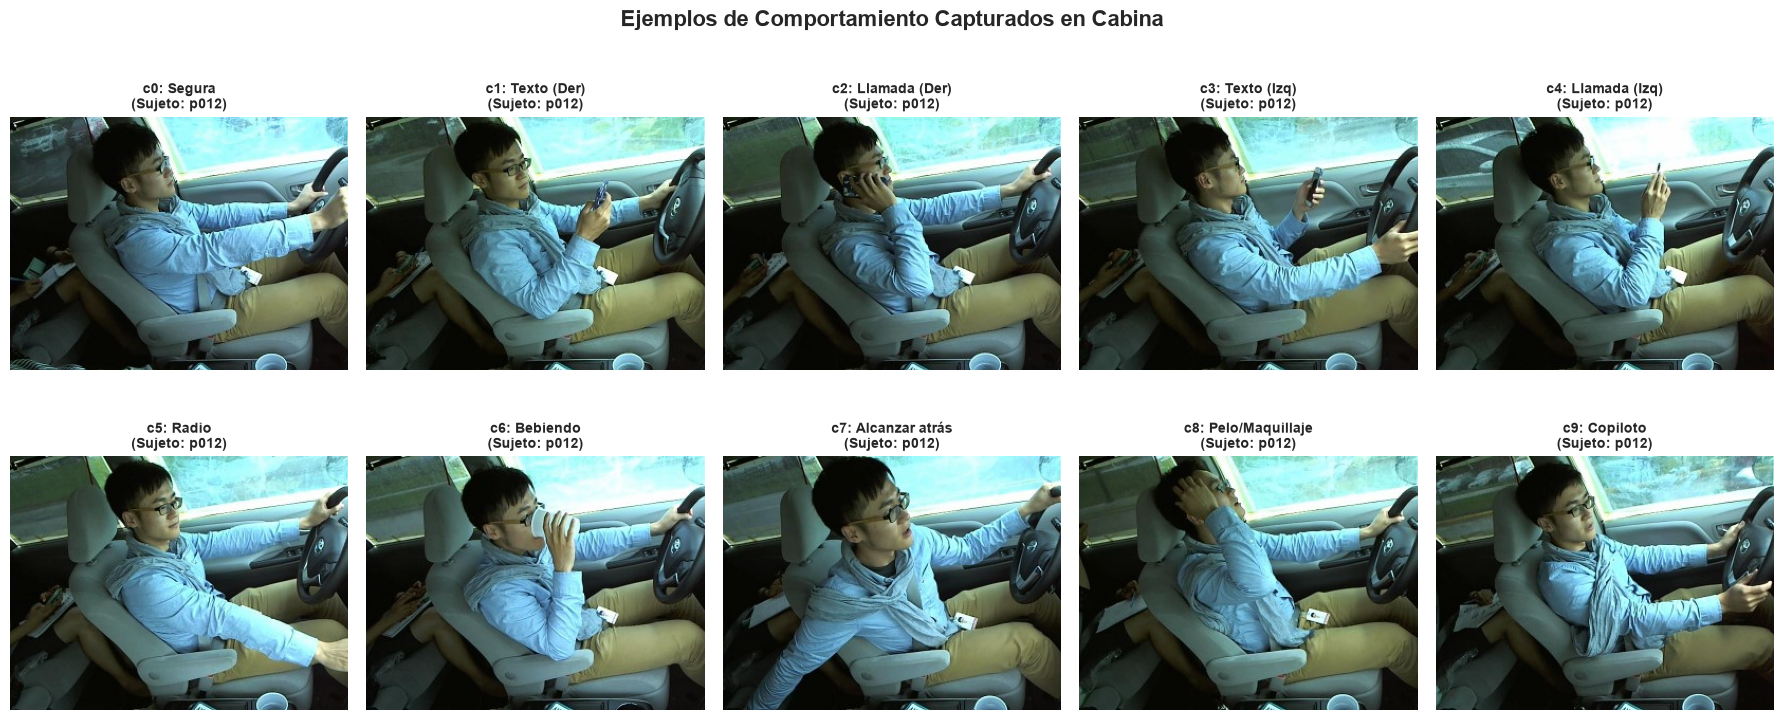

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i, class_id in enumerate(sorted(CLASSES_MAP.keys())):
    # Filtrar una imagen de esa clase
    sample_row = df[df['classname'] == class_id].iloc[0]
    subject = sample_row['subject']
    img_filename = sample_row['img']
    img_path = TRAIN_DIR / class_id / img_filename
    
    # Cargar y graficar
    if img_path.exists():
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f"{class_id}: {CLASSES_MAP_SHORT[class_id]}\n(Sujeto: {subject})", fontsize=10, weight='bold')
    else:
        axes[i].text(0.5, 0.5, f"Ruta no encontrada:\n{img_filename}", ha='center')
        
    axes[i].axis('off')

plt.suptitle('Ejemplos de Comportamiento Capturados en Cabina', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

# Verificación de resoluciones y formatos de imagen

In [8]:
# Comprobación de dimensiones tomando una muestra aleatoria de 50 imágenes
sample_imgs = df.sample(50, random_state=42)
dimensions = set()

for _, row in sample_imgs.iterrows():
    img_path = TRAIN_DIR / row['classname'] / row['img']
    if img_path.exists():
        with Image.open(img_path) as im:
            dimensions.add(im.size) # (ancho, alto)

print("Dimensiones nativas observadas (ancho x alto en píxeles):", dimensions)
print("Formato nativo de compresión:", im.format)

Dimensiones nativas observadas (ancho x alto en píxeles): {(320, 240)}
Formato nativo de compresión: JPEG


Estrategia de partición por sujetos (Split Train / Val / Test)

In [9]:
# Para evitar la fuga de datos (Data Leakage), separamos por SUJETO, no al azar
all_subjects = df['subject'].unique()
np.random.seed(42)
shuffled_subjects = np.random.permutation(all_subjects)

# División: ~70% train (18 sujetos), ~15% val (4 sujetos), ~15% test (4 sujetos)
train_subjects = shuffled_subjects[:18]
val_subjects = shuffled_subjects[18:22]
test_subjects = shuffled_subjects[22:]

df_train = df[df['subject'].isin(train_subjects)]
df_val = df[df['subject'].isin(val_subjects)]
df_test = df[df['subject'].isin(test_subjects)]

print(f"Total Sujetos: {len(all_subjects)}")
print(f"Train: {len(train_subjects)} sujetos -> {len(df_train)} imágenes ({len(df_train)/len(df)*100:.1f}%)")
print(f"Val:   {len(val_subjects)} sujetos -> {len(df_val)} imágenes ({len(df_val)/len(df)*100:.1f}%)")
print(f"Test:  {len(test_subjects)} sujetos -> {len(df_test)} imágenes ({len(df_test)/len(df)*100:.1f}%)")

# Guardar la división limpia en data/processed/ para que el resto del equipo la use
PROCESSED_DIR = BASE_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_train.to_csv(PROCESSED_DIR / "train_split.csv", index=False)
df_val.to_csv(PROCESSED_DIR / "val_split.csv", index=False)
df_test.to_csv(PROCESSED_DIR / "test_split.csv", index=False)

print("\n¡Archivos de división guardados exitosamente en 'data/processed/'!")

Total Sujetos: 20
Train: 18 sujetos -> 31748 imágenes (90.9%)
Val:   2 sujetos -> 3176 imágenes (9.1%)
Test:  0 sujetos -> 0 imágenes (0.0%)

¡Archivos de división guardados exitosamente en 'data/processed/'!
